# 4. H3 as a bridge between datasets

An H3 grid is a raster whose cells have stable IDs. That makes it a convenient meeting point: put
each dataset on the same cells once, then move the joined result to whatever the analysis asks for
(districts, bus stops, streets). This notebook does the three moves UrbanTrace offers from a grid:
to polygons, to points and to lines.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import urbanweave as uw

import tutorial_data as td          # Riverton, the synthetic town these tutorials use
from svgmap import Map              # small static SVG maps
from tutorial_data import show      # prints reports compactly
import diagrams                     # schematic figures of the concepts

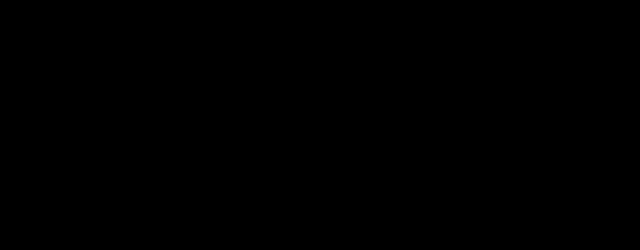

In [2]:
diagrams.grid_to_targets()

In [3]:
import tempfile, os
from urbanweave import streets as uws

districts = td.districts()
crashes = td.crashes()
stops = td.bus_stops()
graph_path = os.path.join(tempfile.mkdtemp(), "riverton.graphml")
td.save_street_graph(graph_path)
street_lines = uws.osm_streets(graphml=graph_path)

cells = uw.targets.h3_cells(crashes.to_crs(4326), 9)
grid = uw.aggregate(uw.match(crashes, cells, "contain"), None,
                    [uw.count(as_="crashes", fill_empty=0), uw.sum("persons_injured", as_="injured", fill_empty=0)])
grid[["target_id", "crashes", "injured"]].head(3)

,target_id,crashes,injured
0,892a12a9803ffff,9,7
1,892a12a9807ffff,4,0
2,892a12a980bffff,7,2


## Grid to polygons: one point per cell, or the overlap

`centroid` sends each whole cell to the district containing its centre; `area_overlap` splits a
cell along district lines. They differ by the cells that straddle a boundary: at resolution 9
(cells of about 0.1 km²) by up to 15 crashes per district here. `centroid` keeps every cell's
crashes, since each cell centre lies in a district; `area_overlap` drops the parts of edge cells that
lie outside the town, about 5 crashes, and its report counts them as unallocated.

In [4]:
by_centroid = uw.aggregate(uw.match(grid, districts, "centroid", target_id="district_id"), None,
                           [uw.sum("crashes", as_="crashes")])
by_area = uw.aggregate(uw.match(grid, districts, "area_overlap", target_id="district_id"), None,
                       [uw.sum("crashes", as_="crashes")])
table = pd.DataFrame({"name": districts["name"], "centroid": by_centroid["crashes"],
                      "area_overlap": by_area["crashes"].round(1)})
print("totals:", table["centroid"].sum(), round(table["area_overlap"].sum(), 1), "| cells:", grid["crashes"].sum())
table

totals: 589 584.0 | cells: 589


,name,centroid,area_overlap
0,Northgate,138,123.3
1,Old Town,211,204.1
2,Eastfield,83,86.1
3,Mill District,60,71.9
4,Riverside,97,98.6


## Grid to points: a cell lookup

`sample` gives each bus stop the value of the cell it falls in. One cell can serve several stops:
values are copied, not split, so this suits intensive values (a rate, a temperature), and summing
them over the stops would count a cell several times. The report says so.

In [5]:
grid["injured_per_crash"] = grid["injured"] / grid["crashes"].where(grid["crashes"] > 0)
m = uw.match(grid, stops, "sample", target_id="stop_id")
at_stops = uw.aggregate(m, None, [uw.first("crashes", as_="cell_crashes"), uw.first("injured_per_crash", as_="cell_injury_rate")])
print("lookup:", m.report["notes"]["lookup"])
at_stops[["stop_id", "cell_crashes", "cell_injury_rate"]].round(2).head()

lookup: h3_index


,stop_id,cell_crashes,cell_injury_rate
0,S00,4,0.5
1,S01,5,0.6
2,S02,4,0.0
3,S03,8,0.125
4,S04,18,0.666667


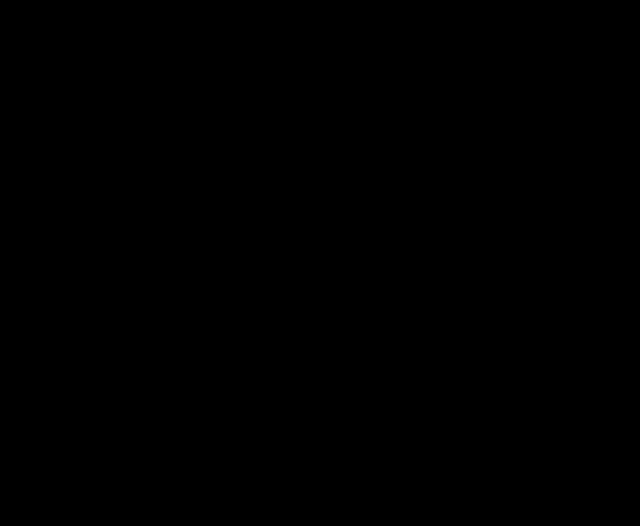

In [6]:
(Map("Each bus stop takes its cell's crash count")
 .fill(grid, "crashes", legend="crashes per cell", classes=5)
 .dots(at_stops, radius=4.5, label="cell_crashes", tooltip=["cell_injury_rate"])
 .outline(districts, width=1.6))

## Grid to lines: length inside each cell

`polygon_to_lines` measures, for each street, the length lying inside each cell. A
`weighted_mean` by that length then gives the average crash count of the cells each street runs
through: an exposure measure along the street. A street lying exactly on a cell edge is counted
once (the cell with the lowest ID owns the edge), so lengths are never doubled.

In [7]:
m = uw.match(grid, street_lines, "polygon_to_lines")
exposure = uw.aggregate(m, None, [uw.weighted_mean("crashes", as_="cell_crashes", valid_measure_as="metres_in_grid")])
exposure[["target_id", "name", "cell_crashes", "metres_in_grid"]].round(1).head()

,target_id,name,cell_crashes,metres_in_grid
0,1-2-0,1st Ave,4.0,178.3
1,1-10-0,A St,4.0,63.6
2,2-3-0,1st Ave,4.0,23.2
3,11-2-0,B St,4.0,250.0
4,3-4-0,1st Ave,5.0,105.9


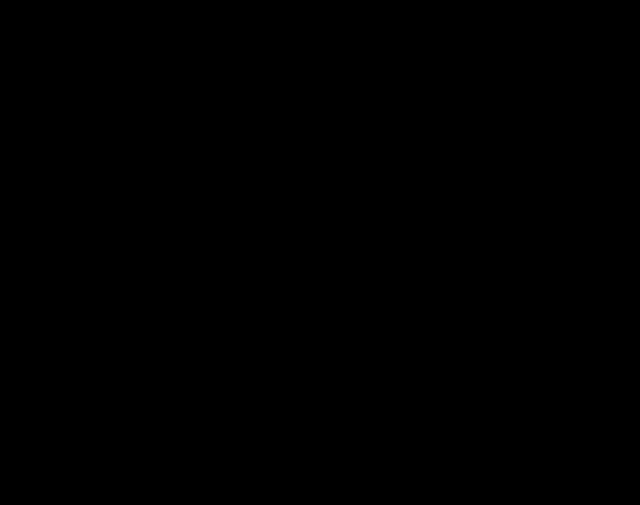

In [8]:
(Map("Streets by the crash count of the cells they cross")
 .lines(exposure, "cell_crashes", legend="mean crashes per cell along the street", width=3, classes=5, tooltip=["name"])
 .outline(districts, label="name", width=1))

## Cells from IDs

A grid can also come from a list of cell IDs, from a file or another tool. `h3_from_cells` checks
that the IDs are valid and share one resolution, and marks the frame as an H3 support so points
are matched by index lookup.

In [9]:
ids = grid.loc[grid["crashes"] >= 20, "target_id"].tolist()
hot = uw.targets.h3_from_cells(ids)
print(len(hot), "cells at resolution", hot.attrs["urbanweave_support"]["resolution"])
try:
    uw.targets.h3_from_cells(["not-a-cell"])
except uw.InputError as err:
    print("InputError —", err)

7 cells at resolution 9
InputError — 'not-a-cell' is not a valid H3 cell.


**Next:** [5. Rasters and zonal statistics](05_rasters_and_zonal_statistics.ipynb).